# Partial

## Subiectul 1 - Modelul Markov ascuns

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

obs_names = ["red", "green", "blue"]
obs = [0, 1, 2, 2, 0] 

pi = np.full(4, 0.25)

B = np.array([[0.7, 0.2, 0.1],
              [0.2, 0.6, 0.2],
              [0.1, 0.3, 0.6],
              [0.5, 0.2, 0.3]])

def make_A(p_stay, p_move):
   
    A = np.zeros((4, 4))
    for i in range(4):
        A[i, i] = p_stay
        A[i, (i - 1) % 4] = p_move
        A[i, (i + 1) % 4] = p_move
    return A

def viterbi(pi, A, B, obs):
    T, N = len(obs), len(pi)
    delta = np.zeros((T, N)); psi = np.zeros((T, N), dtype=int)
    delta[0] = pi * B[:, obs[0]]
    for t in range(1, T):
        cand = delta[t - 1][:, None] * A         
        psi[t] = cand.argmax(axis=0)
        delta[t] = cand.max(axis=0) * B[:, obs[t]]
    path = [int(delta[-1].argmax())]
    for t in range(T - 1, 0, -1):
        path.append(int(psi[t, path[-1]]))
    return path[::-1], delta[-1].max()

def forward(pi, A, B, obs):
    alpha = pi * B[:, obs[0]]
    for o in obs[1:]:
        alpha = (alpha @ A) * B[:, o]
    return alpha.sum()

# a) Robotul ramane pe loc cu probabilitate = 0.2, p(vecin) = 0.4

A_a = make_A(0.2, 0.4)
print("A (a):\n", A_a)
path_a, p_a = viterbi(pi, A_a, B, obs)
print("Secvența de camere (a):", [c + 1 for c in path_a])
print("P(secvență, observații) =", p_a)
print("P(observații) (Forward) =", forward(pi, A_a, B, obs))

# b) Robotul nu ramane pe loc,  p(vecin) = 0.5

A_b = make_A(0.0, 0.5)
print("A (b):\n", A_b)
path_b, p_b = viterbi(pi, A_b, B, obs)
print("Secvența de camere (b):", [c + 1 for c in path_b])
print("P(secvență, observații) =", p_b)
print("P(observații) (Forward) =", forward(pi, A_b, B, obs))
print()
print("Comparație: (a) ->", [c+1 for c in path_a], p_a, "| (b) ->", [c+1 for c in path_b], p_b)


A (a):
 [[0.2 0.4 0.  0.4]
 [0.4 0.2 0.4 0. ]
 [0.  0.4 0.2 0.4]
 [0.4 0.  0.4 0.2]]
Secvența de camere (a): [1, 2, 3, 4, 1]
P(secvență, observații) = 0.00033868799999999997
P(observații) (Forward) = 0.004005000000000001
A (b):
 [[0.  0.5 0.  0.5]
 [0.5 0.  0.5 0. ]
 [0.  0.5 0.  0.5]
 [0.5 0.  0.5 0. ]]
Secvența de camere (b): [1, 2, 3, 4, 1]
P(secvență, observații) = 0.0008268749999999999
P(observații) (Forward) = 0.004139843749999999

Comparație: (a) -> [1, 2, 3, 4, 1] 0.00033868799999999997 | (b) -> [1, 2, 3, 4, 1] 0.0008268749999999999


## Subiectul 2 l-am facut pe foaie

## Subiectul 3 - Inferenta Bayesiana 

prior ~ Beta(2,8) ; 20 produse 5 gasite defecte

Posterior (a): Beta(7, 23), media = 0.2333  (prior: 0.2000)


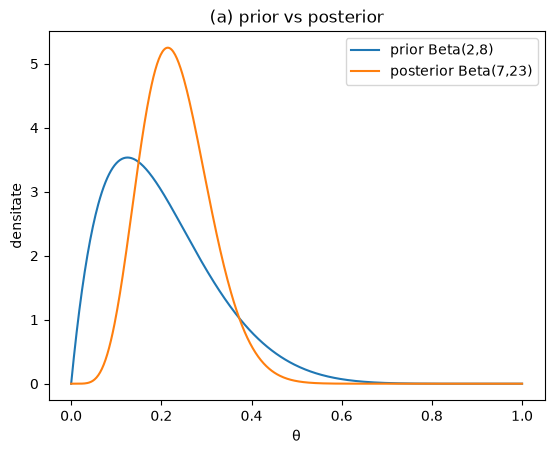

In [6]:
# a) 
a0, b0 = 2, 8
n1, y1 = 20, 5
a1, b1 = a0 + y1, b0 + n1 - y1
print(f"Posterior (a): Beta({a1}, {b1}), media = {a1/(a1+b1):.4f}  (prior: {a0/(a0+b0):.4f})")

x = np.linspace(0, 1, 500)
plt.plot(x, beta.pdf(x, a0, b0), label=f"prior Beta({a0},{b0})")
plt.plot(x, beta.pdf(x, a1, b1), label=f"posterior Beta({a1},{b1})")
plt.xlabel("θ"); plt.ylabel("densitate"); plt.legend(); plt.title("(a) prior vs posterior"); plt.show()

In [7]:
# b) Ambele loturi: lotul 2 cu priorul Beta(2,8)

n2, y2 = 15, 3
a2, b2 = a1 + y2, b1 + n2 - y2
print(f"Posterior (b): Beta({a2}, {b2}), media = {a2/(a2+b2):.4f}")

Posterior (b): Beta(10, 35), media = 0.2222


Posterior (c): Beta(5, 20), media = 0.2000


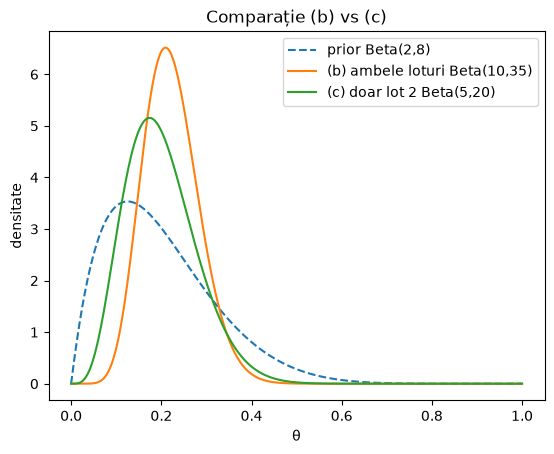

(b) std = 0.0613 | interval credibil 94% = [0.1182 0.3472]
(c) std = 0.0784 | interval credibil 94% = [0.0748 0.3657]


In [8]:
# c) Distributia a posteriori pt lotul 2

a3, b3 = a0 + y2, b0 + n2 - y2
print(f"Posterior (c): Beta({a3}, {b3}), media = {a3/(a3+b3):.4f}")

plt.plot(x, beta.pdf(x, a0, b0), "--", label="prior Beta(2,8)")
plt.plot(x, beta.pdf(x, a2, b2), label=f"(b) ambele loturi Beta({a2},{b2})")
plt.plot(x, beta.pdf(x, a3, b3), label=f"(c) doar lot 2 Beta({a3},{b3})")
plt.xlabel("θ"); plt.ylabel("densitate"); plt.legend(); plt.title("Comparație (b) vs (c)"); plt.show()

for name, (a, b) in {"(b)": (a2, b2), "(c)": (a3, b3)}.items():
    print(name, "std =", round(beta.std(a, b), 4), "| interval credibil 94% =", np.round(beta.interval(0.94, a, b), 4))

In b se folosesc toate cele 35 de observatii cu 8 defecte,deci beta este (10,35) , cu media 0.2222 si incertitudine mai mica. Actualizarea secventiala (lot 1, apoi lot 2) coincide cu cea pe ambele loturi simultan, datorita conjugarii si independentei conditionate de theta. 

In c informatia din primul lot este ignorata, iar posteriorul este Beta(5,20) cu media 0.2 , mai larg(adica mai multa incertitudine) , si mai influentat de prior si de lotul 2. 

Diferenta apare deoarece b) are mai multe date, deci o dispersie mai mica. Media difera pentru ca lotul 1 avea o rata de defecte mai mare (25%) decat lotul 2(20%).